<a href="https://www.kaggle.com/code/qwerty29544/linearregression?scriptVersionId=361413574" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Линейная регрессия в Python
Обсудим модель линейной регрессии, используемую в машинном обучении. Используем ML-техники для изучения взаимосвязи между набором известных показателей и тем, что мы надеемся предсказать. Давайте рассмотрим выбранные для примера данные, чтобы конкретизировать эту идею.

Импортируем рабочие библиотеки и датасет:

In [1]:
import pandas as pd                   # Работа с таблицами в Python
import seaborn as sns                 # Красивая визуализация в Python
import matplotlib.pyplot as plt       # Подробная и гибкая визуализация в Python
import numpy as np                    # Работа с векторами и матрицами
from sklearn.model_selection import learning_curve # Отображение кривой обучения
from sklearn.metrics import make_scorer  # Оценки качества для модели
%matplotlib inline

np.random.seed(43)                     # Фиксируем начальное значение генератора случайных чисел

# Импорт набора данных
data_path = "/kaggle/input/boston-housing-dataset/HousingData.csv"  # Путь к файлу
raw_df = pd.read_csv(data_path).dropna().reset_index()              # Импорт набора данных, удаление пропусков
target = raw_df.MEDV                                                # Выделение прогнозируемого столбца в target
boston_df = raw_df.drop(["index", "MEDV"], axis=1)                  # Удаление прогнозируемого столбца из набора и столбца индекса

## Описание набора данных

- CRIM — уровень преступности на душу населения по городам.
- ZN — доля земли под жилую застройку, разделенная на участки площадью более 25 000 кв. футов.
- INDUS — доля акров, которые принадлежат предприятиям, не связанным с розничной торговлей, на город.
- CHAS — фиктивная переменная реки Чарльз (1, если участок соединен с рекой; 0 в противном случае).
- NOX — концентрация оксидов азота (в десятимиллионных долях).
- RM — среднее количество комнат в доме.
- AGE — доля занимаемых зданий, построенных до 1940 г.
- DIS — взвешенные расстояния до пяти бостонских центров занятости.
- RAD — индекс доступности радиальных автомобильных дорог.
- TAX — полная ставка налога на имущество за каждые 10000 долларов стоимости.
- PTRATIO — соотношение учеников и учителей по городам.
- B — 1000 (Bk — 0,63) , где Bk — доля граждан афроамериканского происхождения по городам.
- LSTAT — процент более низкого статуса населения.
- TARGET —медианное значение стоимости занимаемых домов в тысячах долларов США.

## Задача для данной выборки

Задача данной выборки сводится к прогнозированию целевого показателя **MEDV** (медианной стоимости недвижимости), используя приведенные выше показатели (все, кроме **MEDV**).

In [2]:
raw_df

,index,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,5,0.02985,0.0,2.18,0.0,0.458,6.430,58.7,6.0622,3,222,18.7,394.12,5.21,28.7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
389,499,0.17783,0.0,9.69,0.0,0.585,5.569,73.5,2.3999,6,391,19.2,395.77,15.10,17.5
390,500,0.22438,0.0,9.69,0.0,0.585,6.027,79.7,2.4982,6,391,19.2,396.90,14.33,16.8
391,502,0.04527,0.0,11.93,0.0,0.573,6.120,76.7,2.2875,1,273,21.0,396.90,9.08,20.6
392,503,0.06076,0.0,11.93,0.0,0.573,6.976,91.0,2.1675,1,273,21.0,396.90,5.64,23.9


## Линейная регрессия
Как мы можем подойти к этой проблеме?
Для нашего первого прохода давайте упростим задачу. Допустим, мы просто хотим использовать признак LSAT для прогнозирования TARGET.

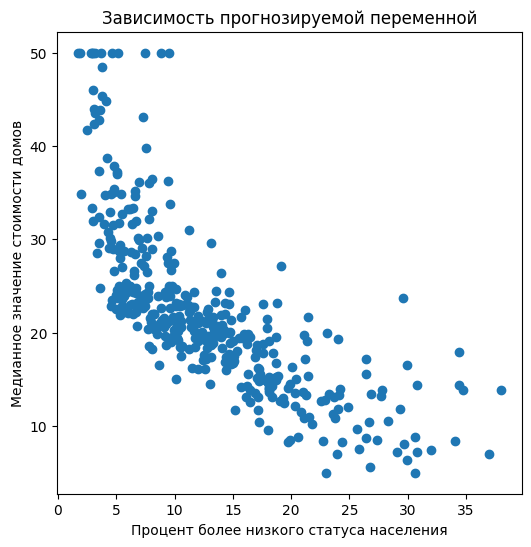

In [3]:
# График зависимости медианной цены дома от района проживания
plt.figure(figsize = (6, 6), dpi = 100)
plt.scatter(boston_df['LSTAT'], target)
plt.xlabel("Процент более низкого статуса населения")
plt.ylabel("Медианное значение стоимости домов")
plt.title("Зависимость прогнозируемой переменной")
plt.show()

По оси X у нас есть LSTAT, а по оси Y — TARGET. Просто взглянув на это, можно увидеть отрицательную взаимосвязь: когда LSTAT растет, TARGET падает.

## Функция оценки/стоимости

Как мы можем решить проблему предсказания TARGET на основе LSTAT? Хорошая отправная точка для размышлений: допустим, мы разрабатываем множество моделей для прогнозирования целевого показателя, как нам выбрать лучшую из них? Как только мы найдем подходящее для сравнения значение, наша задача — минимизировать/максимизировать его.

Это чрезвычайно полезно, если вы можете свести проблему к единственной оценочной метрике. Тогда это очень упрощает цикл разработки модели. Однако в реальном мире прийти к такому упрощению может быть непросто. Иногда не совсем понятно, что вы хотите, чтобы ваша модель максимизировала/минимизировала. Но это проблема для другой статьи.

Поэтому для нашей задачи предлагаю использовать среднюю квадратическую ошибку (mean squared error) в качестве оценочной метрики. Для лучшего понимания смысла MSE, давайте определимся с терминологией:

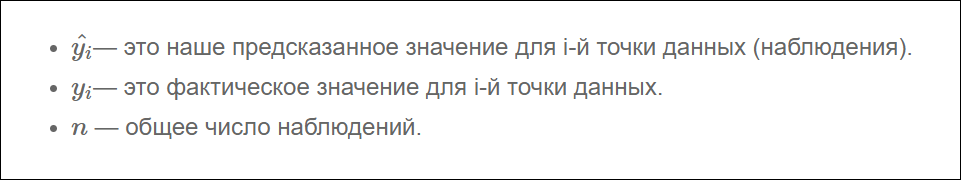

Таким образом, MSE:

$$MSE(\beta)=\frac{1}{n} \sum_{i=1}^{n}(y_i - \hat{y}(x_i, \beta))$$

По сути, для каждой точки мы вычитаем предсказанное нами значение из фактического. Затем, поскольку нас не волнует направление ошибки, мы возводим разницу в квадрат. Наконец, мы вычисляем среднее всех этих значений. Таким образом, мы хотим, чтобы среднее расстояние между предсказанными и фактическими показателями было минимальным.

Вам может быть интересно, почему мы возводили разницу в квадрат вместо того, чтобы брать абсолютное значение. Оказывается, что для некоторых из представленных ниже математических операций возведение в квадрат работает лучше. Кроме того, это метод максимального правдоподобия. Тем не менее, такой подход приводит к тому, что крупные ошибки имеют более сильное влияние на среднее значение, поскольку мы возводим в квадрат каждое отклонение.

## Наша модель

Теперь, когда у нас есть функция оценки, как найти способ ее минимизировать? В этом посте мы рассмотрим модель линейной регрессии. Она выглядит следующим образом:

$$\hat{y}(x_i, \beta) = \beta_0 + \sum_{j=1}^{m}\beta_{j}\cdot x_{j,i}$$

Где $m$ — количество имеющихся у нас предсказателей (независимых переменных), значения бета — это наши коэффициенты. А бета 0 является смещением (intercept). По сути, данная модель представляет собой линейную комбинацию наших предсказателей с intercept.

Теперь, когда у нас есть модель и функция оценки, наша задача состоит в том, чтобы найти бета-значения, которые минимизируют MSE для наших данных. Для линейной регрессии на самом деле существует решение в замкнутой форме, называемое нормальным уравнением. Однако в этом посте мы собираемся использовать другую технику — градиентный спуск.

## Градиентный спуск

Градиентный спуск — это метод, который мы позаимствовали из оптимизации. Очень простой, но мощный алгоритм, который можно использовать для поиска минимума функции.

1. Выберите случайное начальное значение.
2. Делайте шаги, пропорциональные отрицательному градиенту в текущей точке.
3. Повторяйте, пока не достигните предела.

Этот метод найдет глобальный минимум, если функция выпуклая. В противном случае мы можем быть уверены только в том, что достигнем локальный минимум.

Первый вопрос, на который нам нужно ответить: является ли наша функция оценки выпуклой? Давайте посмотрим:

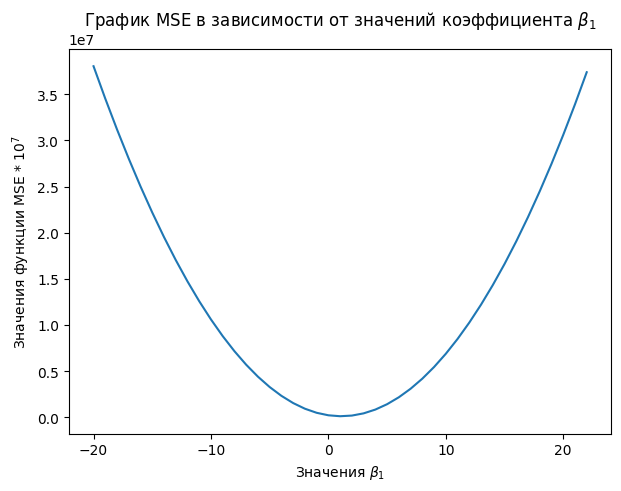

In [4]:
# В коде покажем Функцию минимального квадрата ошибок для коэффициентов beta_1 при LSTAT

mses = []                      # Значения функции MSE
lstat_coef = range(-20, 23)    # Диапазон значений коэффициента beta_1 при LSTAT от -20 до 23

# В цикле для каждого значения подсчитаем предсказания для цены дома
for coef in lstat_coef:
    pred_values = np.array([coef * lstat for lstat in boston_df.LSTAT.values])
    mses.append(np.sum((target - pred_values)**2))
    
plt.figure(figsize = (7, 5), dpi = 100)
plt.plot(lstat_coef, mses)
plt.xlabel(r"Значения $\beta_1$")
plt.ylabel(r"Значения функции MSE * $10^7$")
plt.title(r"График MSE в зависимости от значений коэффициента $\beta_1$")
plt.show()

Для построения графика выше мы взяли диапазон значений коэффициентов для LSTAT, и для каждого из них рассчитали MSE на основе наших данных. Если мы затем отобразим полученные значения, мы получим приведенную выше кривую — выглядит довольно выпуклой! И оказывается, что наша функция MSE с нашей моделью линейной регрессии всегда будет выпуклой! Это означает: мы можем использовать градиентный спуск, чтобы найти оптимальные коэффициенты для нашей модели!

Одна из причин того, что градиентный спуск более распространен, чем нормальное уравнение для машинного обучения, заключается в том, что он намного лучше масштабируется по мере увеличения количества показателей. Это также стандартный метод оптимизации, который используется повсюду в машинном обучении. Поэтому понимание того, как он работает, чрезвычайно важно.

## Градиенты

Если вы снова посмотрите на наш псевдокод для градиентного спуска, вы увидите, что на самом деле все, что нам нужно сделать, это вычислить градиенты. Итак, что такое градиенты? Это просто частные производные по коэффициентам. Для каждого имеющегося коэффициента нам нужно будет вычислить производную MSE по этому коэффициенту. Давайте начнем!

Для начала запишем выражение для MSE, подставив функцию оценки со смещением и единственной переменной LSTAT:

$$MSE(\beta) = \frac{1}{n}\sum_{i=1}^{n} {(y_i - (\beta_0 + \beta_1 \cdot LSTAT_i))^2}$$

Теперь, взяв производную по бета 0, мы получим (умноженное на -1):

$$\frac{\partial MSE}{\partial \beta_0} = \frac{2}{n} \sum_{i=1}^{n}{-1 \cdot (y_i - (\beta_0 + \beta_1 \cdot LSTAT_i))}$$

И для бета 1:

$$\frac{\partial MSE}{\partial \beta_1} = \frac{2}{n} \sum_{i=1}^{n}{-LSTAT_i \cdot (y_i - (\beta_0 + \beta_1 \cdot LSTAT_i))}$$

Теперь давайте запустим наш алгоритм градиентного спуска и убедимся, что MSE действительно уменьшается:

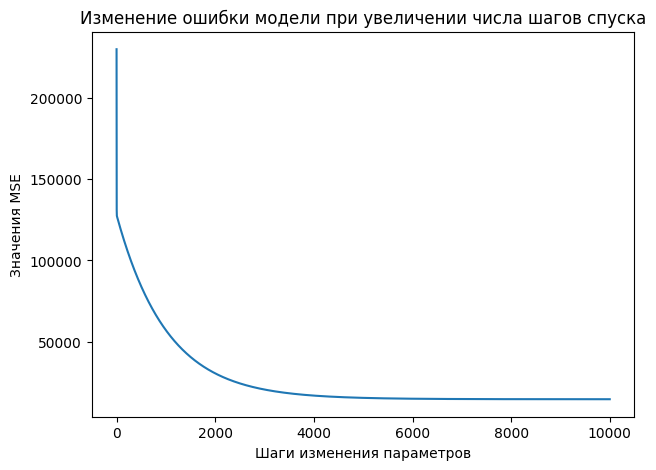

In [5]:
beta_0 = 0                          # Начальное значение для коэффициента beta_0
beta_1 = 0                          # Начальное значение для коэффициента beta_1
learning_rate = 0.001               # Скорость обучения
lstat_values = boston_df.LSTAT.values  # Значения LSTAT
n = len(lstat_values)               # Количество записей данных
all_mse = []                        # Значения MSE

for _ in range(10000):
    predicted = beta_0 + beta_1 * lstat_values    # Прогнозы по модели для очередных beta_0 и beta_1
    residuals = target - predicted                # Ошибки между прогнозируемыми значениями и прогнозами
    all_mse.append(np.sum(residuals**2))          # Подсчёт очередного MSE при очередных beta_0 и beta_1 
    beta_0 = beta_0 - learning_rate * ((2/n) * np.sum(residuals) * -1)  # Изменение beta_0 - смещения
    beta_1 = beta_1 - learning_rate * ((2/n) * residuals.dot(lstat_values) * -1) # Изменение beta_1 - коэффициента угла наклона
    

plt.figure(figsize = (7, 5), dpi=100)
plt.plot(range(len(all_mse)), all_mse)

plt.xlabel("Шаги изменения параметров")
plt.ylabel("Значения MSE")
plt.title("Изменение ошибки модели при увеличении числа шагов спуска")

plt.show()

Первый график, представленный выше, показывает значение MSE, когда мы запускаем градиентный спуск. Как и следовало ожидать, MSE уменьшается со временем по мере выполнения алгоритма. Это означает, что мы постоянно приближаемся к оптимальному решению.

На графике видно, что мы вполне могли завершить работу раньше. MSE переходит в прямую (почти не изменяется) примерно после 4000 итераций.

Beta 0: 33.983799879491315
Beta 1: -0.9151773925240111


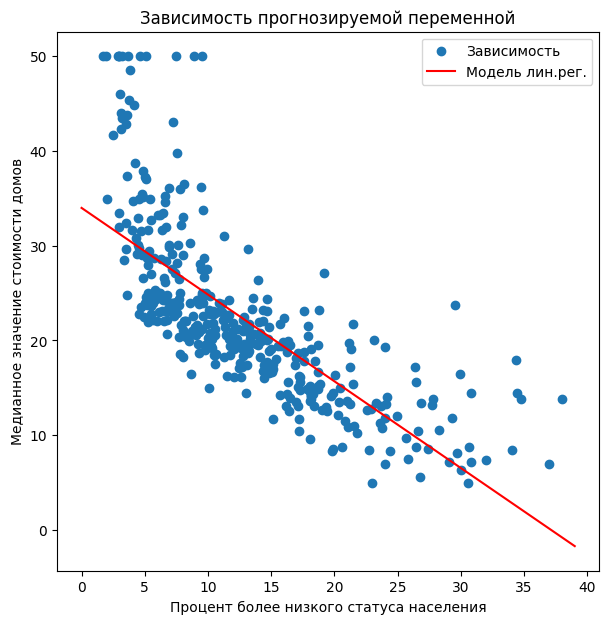

In [6]:
print(f"Beta 0: {beta_0}")
print(f"Beta 1: {beta_1}")

plt.figure(figsize = (7, 7), dpi = 100)
plt.scatter(boston_df['LSTAT'], target, label = "Зависимость")
x = range(0, 40)
plt.plot(x, [beta_0 + beta_1 * l for l in x], c = "red", label = "Модель лин.рег.")
plt.legend()
plt.xlabel("Процент более низкого статуса населения")
plt.ylabel("Медианное значение стоимости домов")
plt.title("Зависимость прогнозируемой переменной")
plt.show()

Итак, запуск градиентного спуска показал, что оптимальное смещение составляет 34.55, а оптимальный наклон равен -0,95. На приведенном выше графике эта линия показана поверх наших данных, она выглядит как аппроксимирующая прямая.

## Скорость обучения
Один параметр, который нам еще предстоит обсудить, — это скорость обучения. Эта скорость — гиперпараметр, используемый для определения того, насколько большие шаги мы делаем от направления градиента. Как узнать, какое значение выбрать? Как правило, можно попробовать множество вариантов. Вот некоторые из них, которые были предложены Andrew Ng: .001, .003, .01, .03, .1, .3, 1, 3.

Выбор слишком малого значения приводит к более медленной сходимости. Выбор слишком большого значения может привести к перешагиванию через минимум и расхождению.

Существуют также другие оптимизаторы градиентного спуска, которые более сложны и адаптируют скорость обучения за вас. Это также то, что вы можете делать самостоятельно, постепенно снижая скорость обучения.

## Когда прекратить итерацию?
В моем коде я просто выполняю наш цикл 10000 раз. Почему 10000? Никакой реальной причины, кроме моей уверенности в том, что этого достаточно, чтобы достичь минимума. Такой подход точно нельзя назвать лучшей практикой. Вот несколько более разумных идей:

Следите за оценкой после каждого цикла, и когда ее очередное изменение меньше некоторого граничного значения — скажем, 0.001 — останавливайтесь.
Используйте проверочный датасет (validation set) и отслеживайте число ошибок, например, с помощью MSE. Когда метрика перестанет уменьшаться, остановитесь.

## Нормализация данных
При работе с градиентным спуском вы хотите, чтобы все ваши данные были нормализованы. Вычтите среднее значение и разделите на стандартное отклонение для всех ваших тренировочных показателей. Обычно это ускоряет обучение и снижает вероятность застревания в локальном оптимуме, если функция оценки не является выпуклой.

## Другие виды градиентного спуска
Показанный здесь градиентный спуск представляет собой классическую форму, что означает: каждое обновление коэффициента использует все данные для вычисления градиентов. Существует также стохастический градиентный спуск. Ему необходима только 1 строка данных (1 наблюдение) для пересчета коэффициентов в каждом цикле.

Такой способ намного лучше масштабируется, так как нужно обработать только одну строку данных за раз перед обновлением. Также он является более неопределенным, поскольку вы пытаетесь перемещаться с использованием градиента, рассчитанного на основе единственного наблюдения.

Другой тип градиентного спуска — это мини-пакетный градиентный спуск. Эта форма представляет собой компромисс между двумя, где вы выбираете размер пакета. Скажем, 32 (или, что еще лучше, пакетный график, который начинается с небольших пакетов и увеличивается с увеличением количества эпох), и каждая итерация вашего градиентного спуска использует 32 случайные строки данных для вычисления градиента (алгоритм воспользуется всеми строками перед повторной выборкой раннее обработанных). В результате мы получаем некоторую масштабируемость, но и некоторую неопределенность.

Такое случайное поведение оказывается полезным для функций оценки, которые не являются выпуклыми (глубокое обучение), поскольку оно может помочь модели избежать локального минимума. Это наиболее распространенный метод для невыпуклых функций оценки.

## Реализация линейной регрессии в Scikit-Learn
Теперь, когда мы немного разбираемся в теории и реализации, давайте обратимся к библиотеке scikit-learn, чтобы на самом деле использовать линейную регрессию на наших данных. Написание моделей с нуля довольно полезно для обучения, но на практике вам, как правило, гораздо лучше использовать проверенную и широко используемую библиотеку.

Для начала нужно нормализовать данные:

In [7]:
from sklearn.linear_model import SGDRegressor           # Линейная модель с градиентным спуском
from sklearn.metrics import mean_squared_error          # Расчет MSE 
from sklearn.preprocessing import StandardScaler        # Стандартизация/Нормализация значений признаков

scaler = StandardScaler()                               # Объект нормализатора, обучаемый fit и применяемый transform
scaler.fit(boston_df)                                   # Обучение нормализатора
scaled_df = scaler.transform(boston_df)                 # Применение нормализатора к набору данных

У Scikit-learn довольно удобный API. Он предоставляет множество моделей, и все они имеют функции fit и predict. Вы можете вызвать fit с вашими X и y данными для обучения модели, а затем использовать predict для получения предсказанных значений на основе новых данных. Scikit-learn также предоставляет множество метрик, которые вы можете использовать для оценки, такие как MSE. Здесь я вычисляю среднеквадратическую ошибку (RMSE). Так мы можем использовать шкалу нашего целевого показателя, что, легче для понимания.


## Матрица корреляции

Матрица корреляции быстро отвечает на вопрос от каких признаков сильнее зависит прогнозируемая переменная. Высокое отрицательное значение говорит о высокой отрицательной зависимости между столбцами, т.е. чем ниже это значение тем больше будет умешьшаться значение показателя с ростом другого. Высокое положительное же значение говорит о сильной положительной линейной связи.

(14.5, -0.5)

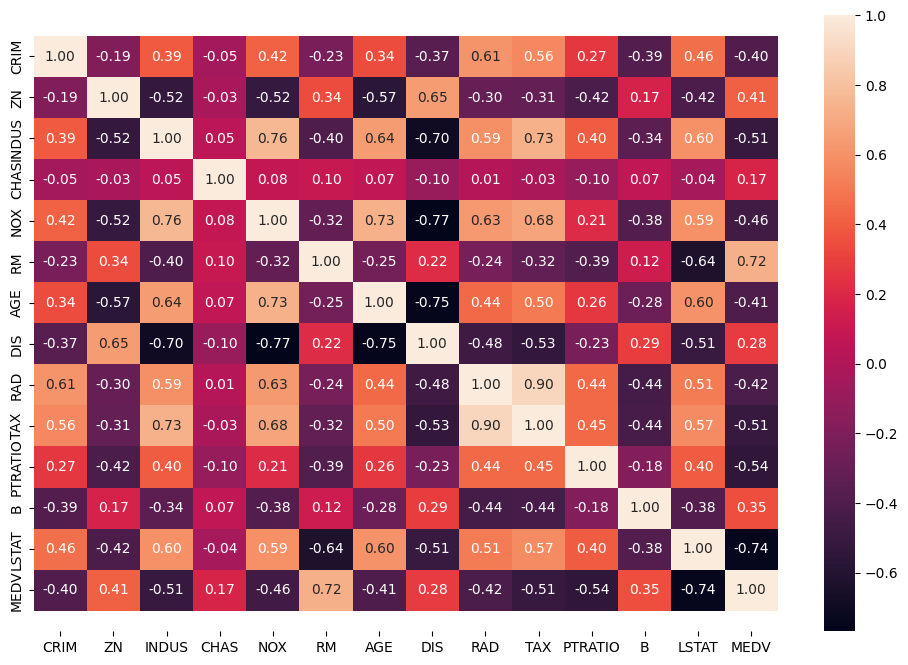

In [8]:
plt.figure(figsize = (12,8))
ax = sns.heatmap(raw_df.drop("index", axis=1).corr(), annot = True, fmt = ".2f")
i, k = ax.get_ylim()
ax.set_ylim(i+0.5, k-0.5)

По последней строке матрицы корреляций заметим высокую положительную линейную связь прогнозируемого столбца MEDV от столбца RM, а также высокую отрицательную связь со столбцом LSTAT. Чем выше по модулю значение корреляции столбца с прогнозируемым столбцом, тем лучше этот признак выглядит в качестве используемого для регрессии

## SGDRegressor
SGDRegressor выполняет линейную регрессию с использованием градиентного спуска и принимает следующие аргументы: tol(сообщает модели, когда следует прекратить итерацию) и eta0(начальная скорость обучения).

In [9]:
linear_regression_model = SGDRegressor(tol=.0001, eta0=.01)   # Модель линейной регрессии с гиперпараметрами
linear_regression_model.fit(scaled_df, target)                # Обучение модели на X = scaled_df и Y = target
predictions = linear_regression_model.predict(scaled_df)      # Получение прогнозных оценок для Y на наборе данных
mse = mean_squared_error(target, predictions)                 # Оценка ошибки
print("MSE: {}".format(np.sqrt(mse)))

MSE: 4.418088628875905


MSE в итоге составила 4.68… для нашей обучающей выборки с использованием scikit-learn.

## Полиномиальные переменные
Рассматривая построенный выше график стоимости от LSTAT, вы могли заметить, что между данными показателями существует полиномиальная связь. Линейная регрессия хорошо подходит в случае линейной зависимости, но, если вы добавите полиномиальные показатели, такие как LSTAT, вы сможете установить более сложные отношения. SKLearn упрощает данный процесс:

In [10]:
from sklearn.preprocessing import PolynomialFeatures          # Класс, применяющий полиномиальное преобразование признаков

poly = PolynomialFeatures(2, include_bias=False)              # Объект, выполняющий преобразования до полинома степени 2

# Новый набор признаков включающий в себя столбцы, возведенные в степень 2 и перемноженные попарно друг с другом
poly_df = poly.fit_transform(boston_df)

scaled_poly_df = scaler.fit_transform(poly_df)                # Нормализатор признаков
print(f"shape: {scaled_poly_df.shape}")

linear_regression_model.fit(scaled_poly_df, target)           # Обучение линейной модели регрессии
predictions = linear_regression_model.predict(scaled_poly_df) # Прогнозные значения на выборке с применением модели
mse = mean_squared_error(target, predictions)                 # Подсчет MSE между TARGET и прогнозом 
print("RMSE: {}".format(np.sqrt(mse)))

shape: (394, 104)
RMSE: 3.049449672922338


Функция PolynomialFeatures сгенерировала новую матрицу признаков, состоящую из всех их полиномиальных комбинаций со степенью меньше или равной указанной (в нашем примере 2). Затем мы нормализовали эти данные и скормили их нашей модели. Так мы получили улучшенную тренировочную RMSE, равную 3.04. Однако обратите внимание, что эти результаты, представленные в иллюстративных целях, используют только тренировочную выборку.

## Категориальные переменные
Линейная регрессия — одна из моделей, с которой нужно быть осторожным, когда у вас есть качественные данные. Если у вас переменные со значениями 1, 2 и 3, которые на самом деле означают «Мужской», «Женский», «Нет ответа», не передавайте их модели таким образом, даже если они являются числами.

Если бы вы это сделали, модель присвоила бы такому показателю коэффициент — возможно, 0.1. Это будет означать, что принадлежность к женскому полу увеличивает предсказанное значение на 0.1. А отсутствие ответа — на 0.2. Но, возможно, метка «Женский» должна повысить результат на 1.2, а «Нет ответа» — всего на 0.001. Чтобы решить данную проблему, вы должны преобразовать такие значения в фиктивные переменные, чтобы каждая категория имела свой собственный вес. Вы можете узнать, как это сделать с помощью scikit-learn, здесь https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html.

## Интерпретация вашей модели
Линейная регрессия — это отличная статистическая модель, которая существует уже давно. Есть много статистических методов, которые можно использовать для ее оценки и интерпретации. Мы не будем рассматривать их все и на самом деле сосредоточимся на очень простых подходах, которые, возможно, более распространены в машинном обучении, чем в статистике.

Во-первых, давайте посмотрим на коэффициенты, которым научилась наша модель (по всем показателям):

In [11]:
linear_regression_model.fit(scaled_df, target) 
sorted(list(zip(boston_df.columns, linear_regression_model.coef_)), 
       key=lambda x: abs(x[1]))

[('INDUS', -0.022043118503425344),
 ('AGE', -0.38832109084679267),
 ('CHAS', 0.7282436880461677),
 ('CRIM', -0.8551809689054607),
 ('B', 0.8706396069117783),
 ('ZN', 1.0884038589205953),
 ('TAX', -1.608370100465471),
 ('NOX', -1.8946125031799903),
 ('RAD', 1.9405512725516232),
 ('PTRATIO', -1.9543850317028626),
 ('DIS', -2.9973044042912806),
 ('RM', 3.0260466179189556),
 ('LSTAT', -3.0913063376919987)]

Что они означают? Каждый коэффициент представляет собой среднее изменение цены на жилье при изменении соответствующего показателя на единицу с условием, что все остальные показатели остаются неизменными. Например, если значения других показателей не затрагиваются, то увеличение LSTAT на единицу снижает наш целевой показатель (цену на жилье) на 3.72, а увеличение RM увеличивает его на 2.85.

Таким образом, если вы хотите повысить стоимость дома, то может быть стоит начать с увеличения RM и уменьшения LSTAT. Я говорю «может быть», потому что линейная регрессия рассматривает корреляции. Судя по нашим данным, такая взаимосвязь имеет место быть, что само по себе не означает обязательное наличие причинно-следственной связи между показателями.

## Доверительные интервалы
Часто в машинном обучении очень полезно иметь доверительный интервал вокруг ваших оценок. Есть разные способы сделать это, но одним довольно общим методом является использование bootstrap.

Bootstrap — это случайная выборка на основе наших данных, и эта выборка того же размера, что и исходные данные. Так мы можем создать несколько представлений одних и тех же данных. Давайте создадим 1000 bootstrap-семплов наших данных.

In [12]:
from sklearn.utils import resample

n_bootstraps = 1000 
bootstrap_X = [] 
bootstrap_y = [] 

for _ in range(n_bootstraps): 
    sample_X, sample_y = resample(scaled_df, target)
    bootstrap_X.append(sample_X) 
    bootstrap_y.append(sample_y)

Затем мы обучим модель на каждом из полученных датасетов и получим следующие коэффициенты:

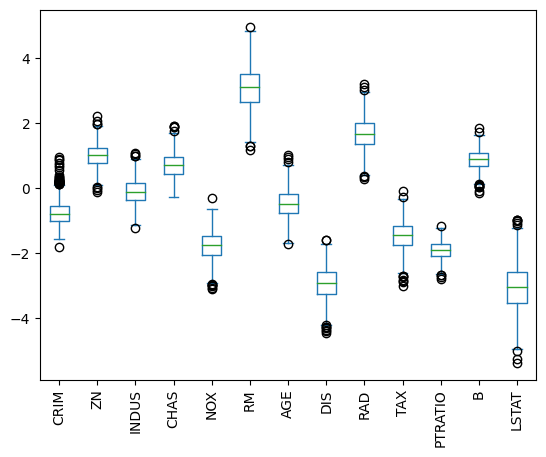

In [13]:
linear_regression_model = SGDRegressor(tol=.0001, eta0=.01)
coeffs = [] 

for i, data in enumerate(bootstrap_X):
    linear_regression_model.fit(data, bootstrap_y[i])
    coeffs.append(linear_regression_model.coef_)
    
coef_df = pd.DataFrame(coeffs, columns=boston_df.columns) 
coef_df.plot(kind='box') 
plt.xticks(rotation=90);

На представленной диаграмме размаха показан диапазон значений коэффициентов, которые мы получили для каждого показателя для всех моделей, которые мы обучили. AGE — особенно интересен, потому что значения коэффициентов были как положительными, так и отрицательными, что является хорошим признаком того, что, вероятно, нет никакой связи между возрастом и стоимостью.

Кроме того, мы можем увидеть, что LSTAT имеет большой разброс в значениях коэффициентов, в то время как PTRATIO имеет относительно небольшую дисперсию, что повышает доверие к нашей оценке этого коэффициента.

Мы даже можем немного углубиться в полученные коэффициенты для LSTAT:

count    1000.000000
mean       -3.042581
std         0.742139
min        -5.365055
25%        -3.542406
50%        -3.034805
75%        -2.587694
max        -0.962168
Name: LSTAT, dtype: float64


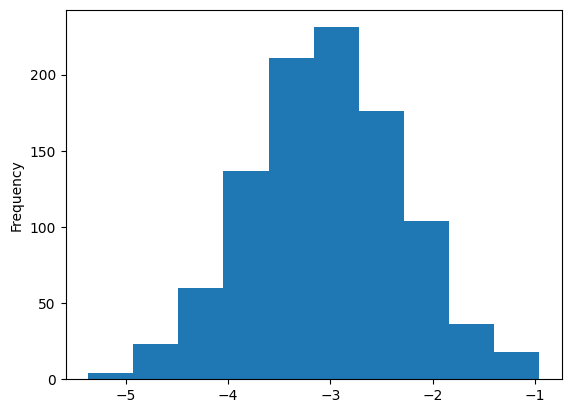

In [14]:
print(coef_df['LSTAT'].describe())
coef_df['LSTAT'].plot(kind='hist');

Теперь мы можем с большой уверенностью сказать, что фактический коэффициент LSTAT отрицателен и почти наверняка находится между -2 и -5.5.

## Разделение на обучающий/тестовый датасеты и кросс-валидация
До этого момента мы тренировались на всех имеющихся данных. Это может иметь смысл, потому что мы хотим максимизировать их полезность, используя как можно больше данных для обучения. С другой стороны, из-за такого подхода нам становится труднее оценивать, насколько хорошо работает наша модель. Причина этого в том, что, если мы продолжим рассчитывать MSE, используя тренировочные данные, мы можем обнаружить, что при применении модели на незнакомых ей данных, она работает довольно плохо.

> Эта идея называется переобучением (overfitting). По сути, такая модель работает намного лучше с обучающими данными, чем с новыми. Она была чрезмерно натренирована на обнаружение уникальных характеристик обучающего множества, которые не являются общими закономерностями, присущими генеральной совокупности.

Другая сторона проблемы называется bias. Модель имеет высокий bias, когда она плохо обучена. В этом случае MSE будет высокой как для тренировочных данных, так и для данных, не показанных во время обучения.

В ML всегда существует компромисс между смещением (bias) и дисперсией (overfitting). По мере того, как ваши модели становятся более сложными, возрастает риск переобучения на тренировочных данных.

Теперь, когда мы знаем о проблемах с вычислением MSE, используя только обучающее множество, что мы можем сделать, чтобы лучше судить о способности модели к обобщению? А также диагностировать overfitting и bias? Типичным решением является разделение наших данных на две части: обучающий и тестовый датасеты.

In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(scaled_df, 
                                                    target, 
                                                    test_size=0.33, 
                                                    random_state=42)

Теперь, когда у нас есть два отдельных набора данных, мы можем тренировать модель на обучающем множестве и вычислять метрики, используя оба датасета (лучше всего использовать ваши тестовые данные после настройки модели):

In [16]:
linear_regression_model = SGDRegressor(tol=.0001, eta0=.01) 
linear_regression_model.fit(X_train, y_train)

train_predictions = linear_regression_model.predict(X_train) 
test_predictions = linear_regression_model.predict(X_test)

train_mse = mean_squared_error(y_train, train_predictions)
test_mse = mean_squared_error(y_test, test_predictions)
print("Train MSE: {}".format(train_mse))
print("Test MSE: {}".format(test_mse))

Train MSE: 16.775863912782988
Test MSE: 26.424146849107203


Отлично! Теперь у нас есть MSE как для тренировочных данных, так и для данных тестирования. И оба значения довольно близки, что говорит об отсутствии проблемы с переобучением. Но достаточно ли они низкие? Большие значения предполагают наличие высокого bias.

Один из способов разобраться в этом — построить график обучения. Кривая обучения отображает нашу функцию ошибок (MSE) с различными объемами данных, используемых для тренировки. Вот наш график:

/opt/conda/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1548: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1548: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1548: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1548: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/linear_model/_stocha

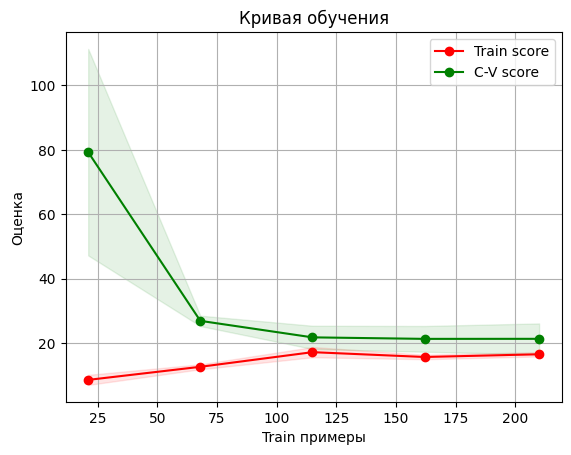

In [17]:
# Источник: http://scikit-learn.org/0.15/auto_examples/plot_learning_curve.html
def plot_learning_curve(estimator, title, X, y, ylim=None, cv=None,
                        n_jobs=1, train_sizes=np.linspace(.1, 1.0, 5)):
 
    plt.figure()
    plt.title(title)
    if ylim is not None:
        plt.ylim(*ylim)
    plt.xlabel("Train примеры")
    plt.ylabel("Оценка")
    train_sizes, train_scores, test_scores = learning_curve(
        estimator, X, y, cv=cv, n_jobs=n_jobs, train_sizes=train_sizes, scoring=make_scorer(mean_squared_error))
    train_scores_mean = np.mean(train_scores, axis=1)
    train_scores_std = np.std(train_scores, axis=1)
    test_scores_mean = np.mean(test_scores, axis=1)
    test_scores_std = np.std(test_scores, axis=1)
    plt.grid()

    plt.fill_between(train_sizes, train_scores_mean - train_scores_std,
                     train_scores_mean + train_scores_std, alpha=0.1,
                     color="r")
    plt.fill_between(train_sizes, test_scores_mean - test_scores_std,
                     test_scores_mean + test_scores_std, alpha=0.1, color="g")
    plt.plot(train_sizes, train_scores_mean, 'o-', color="r",
             label="Train score")
    plt.plot(train_sizes, test_scores_mean, 'o-', color="g",
             label="C-V score")

    plt.legend(loc="best")
    return plt

plot_learning_curve(linear_regression_model, 
                    "Кривая обучения", 
                    X_train, 
                    y_train, 
                    cv=5);

Вы можете видеть, что с менее чем 50 обучающими примерами тренировочная MSE неплохая, а кросс-валидация оставляет желать лучшего — довольно плохая (мы еще не говорили о кросс-валидации, так что пока думайте об этом как о тестировании). Если бы у нас было только такое количество данных, это выглядело бы как явная проблема высокой дисперсии (переобучения).

По мере увеличения наших данных мы начинаем улучшать оба результата, и они становятся очень похожими, что говорит о том, что у нас нет проблемы переобучения. Как правило, при высокой дисперсии на этом графике две линии будут находится довольно далеко друг от друга, и кажется, что, если мы продолжим добавлять больше данных, они могут сойтись.

Этот график больше похож на проблему с большим смещением (bias), поскольку две наши кривые очень близки и сглаживаются. Однако трудно сказать наверняка, потому что, возможно, мы только что достигли наилучшего возможного MSE. В таком случае это не будет проблемой высокого смещения. Такой результат был бы ей только в том случае, если бы наши кривые выровнялись при значении MSE выше оптимального. В реальной жизни вы не знаете, какова оптимальная MSE, поэтому вам нужно немного поразмышлять, считаете ли вы, что уменьшение bias улучшит ваш результат — но лучше просто попробуйте!

## Устранение проблем высоких bias/variance
И1так, теперь, когда вы диагностировали проблему смещения или дисперсии, как ее исправить?

Для высокой дисперсии:

- Получите больше данных для обучения
- Попробуйте меньший набор показателей
- Используйте менее сложную модель
- Добавьте регуляризацию

Для высокого смещения:

- Попробуйте увеличить число показателей
- Перейдите на более сложную модель

## Кросс-валидация и настройка гиперпараметров

Ранее мы упоминали этот термин: кросс-валидация. Давайте поговорим об этом сейчас. На данный момент мы узнали, что неплохо разделить данные на наборы для обучения и тестирования, чтобы лучше понять, насколько хорошо работает модель. Это замечательно, но представьте, что мы хотим протестировать несколько разных моделей или протестировать разные параметры нашей модели — например, другую скорость обучения или толерантность. Как бы нам решить, какая модель или какой параметр лучше? Будем ли мы обучать все на тренировочных данных и тестировать все на наших тестовых данных?

Надеюсь, вы понимаете, что это не имеет смысла, потому что тогда мы, по сути, оказались бы в том же месте, что и раньше, без возможности проверить, насколько хорошо мы справляемся с ранее неизвестными данными. Итак, мы хотим сохранить датасет для тестирования незапятнанным в том смысле, что в идеальном мире мы бы запускали наши тесты на нем только после того, как провели все необходимые эксперименты и были уверены в том, что нашли самую лучшую модель.

Похоже, нам нужен третий набор данных – датасет для валидации. По сути, мы можем разбить наши обучающие данные на две части: обучающий и проверочный датасеты. Все модели будут обучены на тренировочном множестве, а затем протестированы на нашем проверочном наборе. Затем мы выберем модель, которая лучше всего справляется с проверкой, и посмотрим, насколько удачно она пройдет тестирование. Результаты тестирования покажут, как хорошо наша модель будет работать с незнакомыми данными, и на этом мы завершим процесс разработки.

> Примечание: в статье предполагается, что используемые тестовые и проверочные датасеты представляют собой репрезентативные выборки из нашей совокупности. Например, если средняя цена дома в вашем проверочном множестве составляет 1 миллион, а для генеральной совокупности соответствующее значение равно 300 тысячам, у вас плохая выборка. Часто мы случайным образом делим имеющиеся данные на три выборки, но всегда полезно подтвердить, что эти наборы являются репрезентативными. В противном случае вы обнаружите, что ваша модель, которая хорошо зарекомендовала себя при проверке и тестировании, плохо работает на реальных данных.

На практике вместо создания единого множества для проверки мы часто используем k-блочную кросс-валидацию.

Это означает, что мы выбираем значение k, скажем 3. Затем мы берем наши обучающие данные и делим их на 3 части. Мы случайным образом выбираем 2 блока для тренировки, а затем используем оставшийся для тестирования. Повторяем этот процесс еще 2 раза, так чтобы все наблюдения были использованы как для обучения, так и для проверки, и каждое из них применялось для валидации только один раз. После этого усредняем все три оценки (в нашем случае MSE), чтобы получить общую оценку для конкретной модели. Затем мы можем повторить этот процесс для других моделей, чтобы найти лучшую.

Вот видео, которое более наглядно описывает этот подход (с русскими субтитрами): https://www.youtube.com/watch?v=TIgfjmp-4BA

Этот процесс довольно просто реализуется с помощью sklearn:

In [18]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {"eta0": [ .001, .003, .01, .03, .1, .3, 1, 3]} 
linear_regression_model = SGDRegressor(tol=.0001) 
n_iter_search = 8 
random_search = RandomizedSearchCV(linear_regression_model, 
                                   param_distributions=param_dist, 
                                   n_iter=n_iter_search, 
                                   cv=3, 
                                   scoring='neg_mean_squared_error') 
random_search.fit(X_train, y_train) 

print("Лучшие параметры: {}".format(random_search.best_params_)) 
print("Лучшая оценка MSE: {}".format(random_search.best_score_))

Лучшие параметры: {'eta0': 0.001}
Лучшая оценка MSE: -21.854069971678637


/opt/conda/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1548: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1548: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1548: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1548: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


Здесь мы фактически использовали рандомизированный поиск (RandomizedSearchCV), который обычно лучше, чем поиск по всем возможным значениям. Часто вы хотите попробовать много разных параметров для множества различных регуляторов, и сеточный поиск (перебор всех возможных комбинаций) вам не подходит.

Обычно вы хотите использовать рандомизированный поиск (случайный выбор комбинаций), как мы сделали выше. Хотя, поскольку у нас было только небольшое количество значений, мы заставили его работать как сеточный поиск, установив n_iter_search равным числу вариантов, которые мы хотели попробовать.

Мы также установили cv=3, чтобы иметь 3 блока и использовали отрицательную MSE, потому что функции CV в scikit-learn пытаются максимизировать значение.

Вы можете узнать больше о случайном и «сеточном» вариантах поиска здесь: https://scikit-learn.org/stable/modules/grid_search.html.

Кроме того, в scikit-learn есть много других CV функций, которые полезны, особенно если вы хотите протестировать разные модели с одинаковыми блоками. Вот некоторая документация: https://scikit-learn.org/stable/modules/cross_validation.html.

## Регуляризация
В качестве средства борьбы с высокой дисперсией я упомянул регуляризацию. Вы можете думать о ней как о методе, который используется для наказания модели за обучение сложным взаимосвязям. Для линейной регрессии она принимает форму трех популярных подходов. Все эти методы сосредоточены на идее ограничения того, насколько большими могут быть коэффициенты наших показателей.

Идея состоит в том, что если мы переоцениваем влияние предсказателя (большое значение коэффициента), то, вероятно, мы переобучаемся. Примечание: у нас все еще могут быть просто большие коэффициенты. Регуляризация говорит о том, что уменьшение MSE должно оправдывать увеличение значений коэффициентов.

- Регуляризация L1 (Lasso): вы добавляете сумму абсолютных значений коэффициентов к функции оценки. Этот метод может принудительно обнулить коэффициенты, что затем может быть средством выбора показателей.

- Регуляризация L2 (Ridge): вы добавляете сумму квадратов значений коэффициентов к функции оценки.

Каждый из этих методов принимает весовой множитель, который говорит вам, насколько сильное влияние регуляризация будет иметь на функцию оценки. В scikit-learn такой параметр называется альфа. Альфа равный 0 не добавит штрафа, в то время как высокое его значение будет сильно наказывать модель за наличие больших коэффициентов. Вы можете использовать кросс-валидацию, чтобы найти хорошее значение для альфа.
Sklearn упрощает это:

In [19]:
from sklearn.linear_model import RidgeCV

clf = RidgeCV(alphas=[.1, 1, 10]) 
clf.fit(X_train, y_train) 

train_predictions = clf.predict(X_train) 
test_predictions = clf.predict(X_test) 
print("Train MSE: {}".format(mean_squared_error(y_train, train_predictions)))
print("Test MSE: {}".format(mean_squared_error(y_test, test_predictions)))

Train MSE: 16.919189787785026
Test MSE: 26.89029198668456


Здесь мы использовали функцию RidgeCV, которая имеет встроенную кросс-валидацию, чтобы выбрать лучшее значение для альфы.